In [10]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [11]:
rows = []

with open("imdb_movies_2000to2022.prolific.json", "r") as infile:
    for line in infile:

        movie = json.loads(line)

        rating = movie["rating"]

        if not isinstance(rating, dict):
            continue

        if "avg" not in rating or "votes" not in rating:
            continue

        if movie["runtime"] == "\\N":
            continue

        rows.append({
            "imdb_id": movie["imdb_id"],
            "title": movie["title"],
            "year": int(movie["year"]),
            "runtime": int(movie["runtime"]),
            "rating": float(rating["avg"]),
            "votes": int(rating["votes"]),
            "genres": movie["genres"]
        })

movies_df = pd.DataFrame(rows)

movies_df.head()

,imdb_id,title,year,runtime,rating,votes,genres
0,tt0035423,Kate & Leopold,2001,118,6.4,85923,"[Comedy, Fantasy, Romance]"
1,tt0088751,The Naked Monster,2005,100,5.3,328,"[Comedy, Horror, Sci-Fi]"
2,tt0096056,Crime and Punishment,2002,126,5.6,830,[Drama]
3,tt0113092,For the Cause,2000,100,3.4,829,"[Action, Adventure, Drama]"
4,tt0116391,Gang,2000,167,6.2,257,"[Action, Crime, Drama]"


In [12]:
print("Number of movies:", len(movies_df))

movies_df.head()

Number of movies: 17967


,imdb_id,title,year,runtime,rating,votes,genres
0,tt0035423,Kate & Leopold,2001,118,6.4,85923,"[Comedy, Fantasy, Romance]"
1,tt0088751,The Naked Monster,2005,100,5.3,328,"[Comedy, Horror, Sci-Fi]"
2,tt0096056,Crime and Punishment,2002,126,5.6,830,[Drama]
3,tt0113092,For the Cause,2000,100,3.4,829,"[Action, Adventure, Drama]"
4,tt0116391,Gang,2000,167,6.2,257,"[Action, Crime, Drama]"


In [13]:
movies_df["high_rated"] = (
    movies_df["rating"] >= 7.0
).astype(int)

movies_df[
    ["title", "rating", "high_rated"]
].head(10)

,title,rating,high_rated
0,Kate & Leopold,6.4,0
1,The Naked Monster,5.3,0
2,Crime and Punishment,5.6,0
3,For the Cause,3.4,0
4,Gang,6.2,0
5,Still Waters Burn,6.8,0
6,The Attic Expeditions,4.9,0
7,Chinese Coffee,7.1,1
8,The Dancer Upstairs,6.9,0
9,Don's Plum,5.6,0


In [14]:
movies_df["high_rated"].value_counts()

,count
high_rated,
0,14912
1,3055


In [15]:
movies_df["high_rated"].value_counts(
    normalize=True
)

,proportion
high_rated,
0,0.829966
1,0.170034


In [16]:
all_genres = sorted({
    genre
    for genres in movies_df["genres"]
    for genre in genres
})

for genre in all_genres:
    movies_df[genre] = movies_df["genres"].apply(
        lambda genres: 1 if genre in genres else 0
    )

In [17]:
feature_columns = [
    "year",
    "runtime",
    "votes"
] + all_genres

X = movies_df[feature_columns]
y = movies_df["high_rated"]

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 14373
Testing samples: 3594


In [19]:
model = DecisionTreeClassifier(
    max_depth=6,
    random_state=42
)

model.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=6, random_state=42)

In [20]:
y_pred = model.predict(X_test)

In [21]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

print("Test Accuracy:", accuracy)

Test Accuracy: 0.8689482470784641


In [22]:
print(
    classification_report(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

           0       0.89      0.96      0.92      2983
           1       0.68      0.43      0.53       611

    accuracy                           0.87      3594
   macro avg       0.79      0.70      0.73      3594
weighted avg       0.86      0.87      0.86      3594



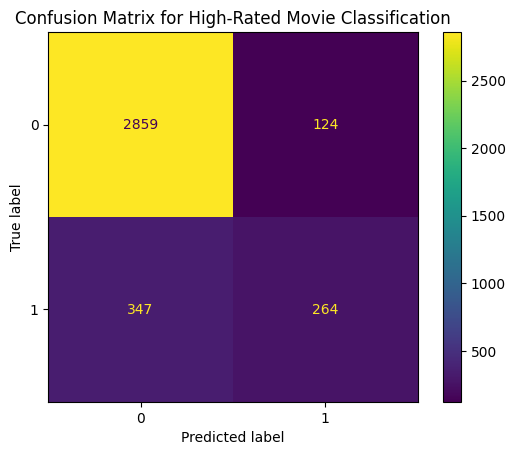

In [23]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred
)

plt.title(
    "Confusion Matrix for High-Rated Movie Classification"
)

plt.savefig(
    "movie_rating_confusion_matrix.png",
    bbox_inches="tight"
)

plt.show()

In [24]:
feature_importance = pd.Series(
    model.feature_importances_,
    index=feature_columns
).sort_values(
    ascending=False
)

feature_importance.head(15)

,0
votes,0.469693
Documentary,0.214140
runtime,0.163913
Drama,0.079116
Horror,0.023516
year,0.011676
Animation,0.008856
Adventure,0.006273
Biography,0.005794
History,0.005137


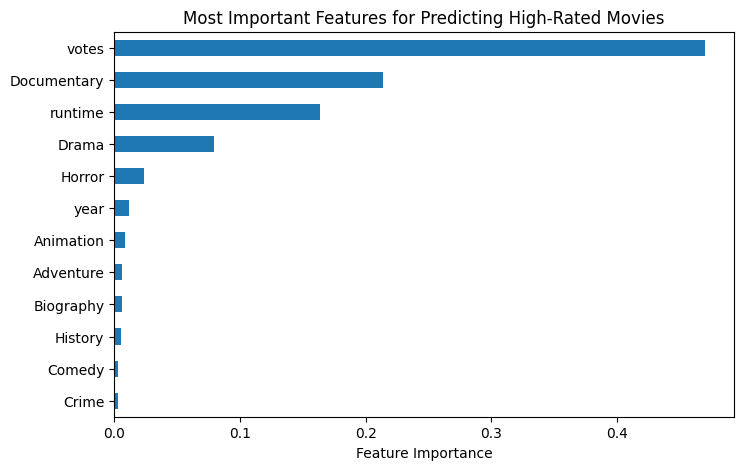

In [25]:
top_features = feature_importance.head(12)

plt.figure(figsize=(8, 5))

top_features.sort_values().plot(
    kind="barh"
)

plt.xlabel("Feature Importance")
plt.title(
    "Most Important Features for Predicting High-Rated Movies"
)

plt.savefig(
    "movie_rating_feature_importance.png",
    bbox_inches="tight"
)

plt.show()

In [26]:
test_results = movies_df.loc[X_test.index].copy()

test_results["predicted"] = y_pred
test_results["actual"] = y_test

wrong_predictions = test_results[
    test_results["predicted"]
    != test_results["actual"]
]

print(
    "Number of incorrect predictions:",
    len(wrong_predictions)
)

Number of incorrect predictions: 471


In [27]:
wrong_samples = wrong_predictions[
    [
        "imdb_id",
        "title",
        "year",
        "runtime",
        "rating",
        "votes",
        "genres",
        "actual",
        "predicted"
    ]
].head(5)

wrong_samples

,imdb_id,title,year,runtime,rating,votes,genres,actual,predicted
9564,tt1764646,The Dome of Heaven,2011,89,7.6,26,[Drama],1,0
16974,tt8041276,Paddleton,2019,89,7.1,14390,"[Comedy, Drama]",1,0
13266,tt3678782,Badlapur,2015,134,7.4,24469,"[Action, Crime, Drama]",1,0
1392,tt0297470,Wrong Numbers,2001,75,7.6,52,[],1,0
3825,tt0488508,The Call of Wild,2006,86,6.9,1899,"[Documentary, Family]",0,1


In [28]:
movies_df.to_csv(
    "constructed_movie_supervision_dataset.csv",
    index=False
)

wrong_samples.to_csv(
    "five_misclassified_movies.csv",
    index=False
)

feature_importance.to_csv(
    "feature_importance.csv"
)